# Part 5:  Vibe-Coding Emerging Optimizers on CIFAR Classification 

As large language models (LLMs) reshape software engineering, we are entering a new era of AI-assisted programming where human creativity and machine execution merge. Instead of focusing on every low-level implementation detail, developers can prioritize **ideas, exploration, and iteration speed**, while the model handles much of the routine coding. This is the essence of [**vibe coding**](https://en.wikipedia.org/wiki/Vibe_coding?utm_source=chatgpt.com): coding by “vibes” and letting AI accelerate the path from concept to working system. In this homework, you will practice vibe coding by using AI assistants such as [ChatGPT](https://chat.openai.com), [Gemini](https://gemini.google.com/app), or [Claude](https://www.anthropic.com/claude-code) to help design and implement optimizers for CIFAR image classification.  

---

## 1. What is *Vibe Coding*? 

**Vibe coding** is a paradigm popularized by Andrej Karpathy in 2025. It emphasizes generating most of the code through LLMs while the human programmer acts as a **guide, tester, and refiner**. Instead of carefully reviewing every line, you iterate based on execution results, keeping the creative process at the center.  

Karpathy put it simply:  
> *“Fully giving in to the vibes, embracing exponentials, and forgetting that the code even exists.”*  

**Learn more :**
- [IBM: What is Vibe Coding?](https://www.ibm.com/think/topics/vibe-coding?utm_source=chatgpt.com)  
- [Replit Blog: What is Vibe Coding?](https://blog.replit.com/what-is-vibe-coding?utm_source=chatgpt.com)  

---

## 2. Objectives 

- Understand and implement **novel optimizers** (Muon, Scion, SODA).  
- Practice **vibe coding** as a workflow with LLMs.  
- Compare optimizer performance on **CIFAR-10** across Transformer and ResNet architectures.  
- Analyze results critically and reflect on the coding process.  

---

## 3. Task Overview 

You will implement and compare four optimizers on **CIFAR-10 classification** with two architectures: a **Transformer**  and a **ResNet** .  

- **Optimizers**: Muon , Scion , SODA , Adam (baseline)  
- **Models**: Transformer, ResNet  
- **Comparison metrics**: convergence speed, final test accuracy , training stability  

---

## 4. Optimizers to Implement 

### (1) Muon 
Muon applies **Newton–Schulz orthonormalization** to gradient updates of 2D weight matrices, making them invariant to input conditioning.  
References:  
- [Muon Blog (Keller Jordan)](https://kellerjordan.github.io/posts/muon/?utm_source=chatgpt.com)  
- [Deriving Muon (Jeremy Bernstein)](https://jeremybernste.in/writing/deriving-muon?utm_source=chatgpt.com)  
- [Muon GitHub Repo](https://github.com/KellerJordan/Muon?utm_source=chatgpt.com)  
- [Convergence Bound (arXiv)](https://arxiv.org/abs/2507.01598?utm_source=chatgpt.com)  

---

### (2) Scion 
Scion constrains updates differently for hidden vs input/output layers, using **spectral norm** for hidden layers and **ℓ∞ norm** for others. This improves stability and hyperparameter transfer.  
References:  
- [Scion Paper](https://arxiv.org/abs/2502.07529)  
- [Scion Official Code](https://github.com/LIONS-EPFL/scion)  

---

### (3) SODA 
SODA wraps a base optimizer with a theoretically grounded, initialization-centered **1/k weight-decay schedule**, motivating us to test whether it improves CIFAR-10 training without tuning weight decay.  
References:  
- [SODA Paper (arXiv)](https://arxiv.org/pdf/2605.11172)  
- [SODA GitHub Repo](https://github.com/tmpethick/soda_code)  

---

### (4) Adam 
Adam is the standard baseline optimizer combining momentum and adaptive learning rates. Use either `Adam` or `AdamW` from PyTorch.

---

## 5. Steps & Deliverables 

1. **Model Implementation (5 pts)**  
   - Build a Transformer for CIFAR classification.  
   - Build a ResNet (ResNet-18 or similar).  

2. **Optimizer Integration (8 pts)**  
   - Implement Muon, Scion, SODA optimizers using your AI assistant in a form which is compatible with `torch.optim.Optimizer`.  
   - Use Adam as baseline.  

3. **Training & Evaluation (7 pts)**  
   - Train both models with all optimizers.  
   - Collect metrics: training loss, validation accuracy, time-to-accuracy.  
   - Present results with plots and a summary table.  

4. **Discussion & Reflection (5 pts)**  
   - Compare optimizers in terms of convergence speed, stability, and accuracy.  
   - Reflect on your experience using **vibe coding** with AI assistants.  
   - What worked well? What challenges did you face?  

---

Good luck and enjoy vibe-coding your way through optimizers!!


## Setup

In [1]:
# Install dependencies if needed:
# %pip install torch torchvision matplotlib numpy

import json
import math
import os
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as transforms
from IPython.display import Markdown, display

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(os.cpu_count() or 4)
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | "
      f"device: {device} | CPU threads: {torch.get_num_threads()}")

torch 2.14.1+cpu | torchvision 0.29.1+cpu | device: cpu | CPU threads: 4


### Experimental protocol

We only have a laptop CPU, so we use a reduced but controlled protocol:

- **Data.** 10,000 random CIFAR-10 training images for training (random crop and horizontal flip), a disjoint set of 2,000 training images for validation (no augmentation), and the full 10,000-image test set, used only once at the end of each final run.
- **Learning-rate tuning.** The optimizers live on different learning-rate scales (Muon and Scion produce normalized updates, Adam does not), so one shared learning rate would not be a fair comparison. Every optimizer gets the same tuning budget: three learning rates, 2 epochs each, selected on the validation set. SODA reuses Adam's learning rate, because its selling point is that it does not need any weight-decay tuning on top of the base optimizer.
- **Final runs.** 6 epochs, batch size 128, per-step cosine learning-rate schedule, 2 seeds per configuration (the seed changes the initialization, the data order and the augmentation).
- **Metrics.** Training loss and validation accuracy after every epoch, wall-clock training time (evaluation excluded), time to reach a target validation accuracy, and the final test accuracy.

In [2]:
# The official CIFAR-10 server is very slow from our network, so we download the same archive from a mirror.
# torchvision verifies the MD5 checksum of the archive, so the data is identical to the official release.
torchvision.datasets.CIFAR10.url = "https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz"
DATA_ROOT = "./data"

CIFAR_MEAN, CIFAR_STD = (0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

train_full = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, download=True, transform=transform_train)
train_full_eval = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, download=False, transform=transform_test)
test_set = torchvision.datasets.CIFAR10(DATA_ROOT, train=False, download=True, transform=transform_test)

# CPU-only budget: we train on a random subset of the training set and hold out a disjoint validation
# subset (same images, without augmentation) for model selection. The full 10,000-image test set is
# used only once, at the end of each final run.
N_TRAIN, N_VAL = 10_000, 2_000
perm = np.random.default_rng(0).permutation(len(train_full))
train_set = Subset(train_full, perm[:N_TRAIN])
val_set = Subset(train_full_eval, perm[N_TRAIN:N_TRAIN + N_VAL])

BATCH_SIZE = 128
val_loader = DataLoader(val_set, batch_size=500, shuffle=False, num_workers=0)
test_loader = DataLoader(test_set, batch_size=500, shuffle=False, num_workers=0)
print(f"train: {len(train_set)} images | validation: {len(val_set)} images | test: {len(test_set)} images")

train: 10000 images | validation: 2000 images | test: 10000 images


## Model implementation

We use two architectures of similar cost on CPU:

- **Transformer**: a small Vision Transformer. A strided convolution cuts the 32×32 image into 4×4 patches (64 tokens); a learnable [CLS] token and positional embeddings are added; then come 3 pre-norm encoder layers (width 64, 4 heads, MLP width 128, dropout 0.1) and a linear head on the [CLS] token.
- **ResNet**: the ResNet-18 layout (4 stages of 2 basic blocks with batch normalization) adapted to 32×32 inputs (3×3 first convolution, no max-pooling). We use base width 16 instead of 64 so that training fits our CPU budget.

`split_params` groups the parameters by role (input layer, hidden matrices, output layer, vector-like parameters), because Muon and Scion treat these groups differently.

In [3]:
class CIFARTransformer(nn.Module):
    """Small Vision Transformer: 4x4 patches -> 64 tokens + [CLS] token, pre-norm encoder, linear head."""

    INPUT_PARAMS = ("patch_embed.weight",)
    OUTPUT_PARAMS = ("head.weight",)

    def __init__(self, img_size=32, patch_size=4, in_channels=3, num_classes=10,
                 embed_dim=64, depth=3, num_heads=4, mlp_ratio=2.0, dropout=0.1):
        super().__init__()
        num_patches = (img_size // patch_size) ** 2

        self.patch_embed = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        self.pos_drop = nn.Dropout(p=dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=int(embed_dim * mlp_ratio),
            dropout=dropout,
            activation='gelu',
            batch_first=True,
            norm_first=True
        )
        self.blocks = nn.TransformerEncoder(encoder_layer, num_layers=depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def forward(self, x):
        B = x.shape[0]
        x = self.patch_embed(x).flatten(2).transpose(1, 2)
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)
        x = self.pos_drop(x + self.pos_embed)

        x = self.blocks(x)
        x = self.norm(x[:, 0])
        return self.head(x)

In [4]:
class BasicBlock(nn.Module):
    def __init__(self, in_planes, planes, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, planes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes)
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return F.relu(out)


class CIFARResNet(nn.Module):
    """ResNet-18 layout (4 stages x 2 BasicBlocks) for 32x32 inputs, with base width 16 instead of 64
    so that training fits a CPU budget."""

    INPUT_PARAMS = ("conv1.weight",)
    OUTPUT_PARAMS = ("linear.weight",)

    def __init__(self, num_blocks=(2, 2, 2, 2), num_classes=10, base_width=16):
        super().__init__()
        self.in_planes = base_width
        self.conv1 = nn.Conv2d(3, base_width, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(base_width)
        self.layer1 = self._make_layer(base_width, num_blocks[0], stride=1)
        self.layer2 = self._make_layer(base_width * 2, num_blocks[1], stride=2)
        self.layer3 = self._make_layer(base_width * 4, num_blocks[2], stride=2)
        self.layer4 = self._make_layer(base_width * 8, num_blocks[3], stride=2)
        self.linear = nn.Linear(base_width * 8, num_classes)

    def _make_layer(self, planes, num_blocks, stride):
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for s in strides:
            layers.append(BasicBlock(self.in_planes, planes, s))
            self.in_planes = planes
        return nn.Sequential(*layers)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = F.adaptive_avg_pool2d(out, (1, 1))
        out = out.view(out.size(0), -1)
        return self.linear(out)

In [5]:
MODELS = {"Transformer": CIFARTransformer, "ResNet": CIFARResNet}


def split_params(model):
    """Group the parameters by role, because Muon and Scion treat them differently.

    input:  first layer (patch embedding / first convolution)
    hidden: all other weight matrices and convolution kernels
    output: classification head
    vector: biases, normalization gains, [CLS] token and positional embedding
    """
    roles = {"input": [], "hidden": [], "output": [], "vector": []}
    for name, p in model.named_parameters():
        if name in model.INPUT_PARAMS:
            roles["input"].append(p)
        elif name in model.OUTPUT_PARAMS:
            roles["output"].append(p)
        elif p.ndim >= 2 and p.shape[0] > 1:
            roles["hidden"].append(p)
        else:
            roles["vector"].append(p)
    return roles


for model_name, model_cls in MODELS.items():
    roles = split_params(model_cls())
    counts = {role: sum(p.numel() for p in ps) for role, ps in roles.items()}
    print(f"{model_name:12s}: {sum(counts.values()):>7,} parameters | by role: {counts}")

Transformer : 108,554 parameters | by role: {'input': 3072, 'hidden': 98304, 'output': 640, 'vector': 6538}
ResNet      : 701,466 parameters | by role: {'input': 432, 'hidden': 697344, 'output': 1280, 'vector': 2410}


## Optimizer integration

All three optimizers subclass `torch.optim.Optimizer`, accept parameter groups, and work with PyTorch learning-rate schedulers and `state_dict()`. Each one follows its reference implementation:

- **Muon** ([KellerJordan/Muon](https://github.com/KellerJordan/Muon)). Nesterov momentum (0.95); the update of each hidden weight matrix is replaced by its approximate orthogonal factor $UV^\top$, computed with 5 quintic Newton–Schulz iterations, and scaled by $\sqrt{\max(1, \text{rows}/\text{cols})}$. Convolution kernels are flattened to $(c_\text{out}, c_\text{in}k^2)$. As the authors recommend, the input layer, the output layer and all vector-like parameters are trained by an auxiliary AdamW inside the same optimizer.
- **Scion** ([LIONS-EPFL/scion](https://github.com/LIONS-EPFL/scion)). The update is the linear minimization oracle (LMO) of a norm ball chosen per layer:
  - spectral norm for the input and hidden layers, scaled by $\sqrt{d_\text{out}/d_\text{in}}$ and divided by $k^2$ for convolution kernels;
  - sign / $\ell_\infty$ geometry for the output layer;
  - RMS normalization for biases, gains and embeddings.

  We use the relative radii of the official CNN example (output layer 16× larger), the unconstrained variant (uSCG), and momentum weight 0.1, the default recommended by the authors.
- **SODA** ([tmpethick/soda_code](https://github.com/tmpethick/soda_code)). A wrapper around Adam without weight decay. After every base step it pulls the weights back towards their initialization $z_0$ with coefficient $1/(k+2)$: $x_{k+1} = \mathrm{AdamStep}(x_k) + \frac{1}{k+2}(z_0 - x_k)$.
- **Adam** baseline: `torch.optim.AdamW` with PyTorch's default weight decay 0.01.

The sanity-check cell verifies three things: the Newton–Schulz output, the `torch.optim.Optimizer` interface of every optimizer, and that our SODA matches the closed form of the reference wrapper.

In [6]:
def zeropower_via_newtonschulz5(G, steps=5, eps=1e-7):
    """Approximate the orthogonal factor U V^T of G = U S V^T with the quintic Newton-Schulz iteration
    of Jordan et al. (2024). The coefficients are tuned for speed rather than exact convergence, so the
    singular values of the result lie roughly in [0.7, 1.2] instead of being exactly 1."""
    assert G.ndim == 2
    a, b, c = (3.4445, -4.7750, 2.0315)
    X = G.bfloat16() if G.is_cuda else G.float()  # bfloat16 matmuls are slow on CPU
    transposed = G.size(0) > G.size(1)
    if transposed:
        X = X.T
    X = X / (X.norm() + eps)
    for _ in range(steps):
        A = X @ X.T
        B = b * A + c * (A @ A)
        X = a * X + B @ X
    if transposed:
        X = X.T
    return X.to(G.dtype)


class Muon(torch.optim.Optimizer):
    """Muon (Jordan et al., 2024) with an auxiliary AdamW, following `SingleDeviceMuonWithAuxAdam`
    from github.com/KellerJordan/Muon.

    Groups with use_muon=True (hidden weight matrices; conv kernels are flattened to 2D):
        b <- mu * b + (1 - mu) * g,   u = (1 - mu) * g + mu * b (Nesterov),
        x <- (1 - lr * wd) * x - lr * sqrt(max(1, rows / cols)) * NewtonSchulz(u)
    Groups with use_muon=False (input layer, output layer, biases, norms, embeddings): AdamW,
    as recommended by the authors, because orthogonalization is only meaningful for hidden matrices.
    """

    def __init__(self, param_groups):
        for group in param_groups:
            if group["use_muon"]:
                group.setdefault("lr", 0.02)
                group.setdefault("momentum", 0.95)
                group.setdefault("nesterov", True)
                group.setdefault("ns_steps", 5)
                group.setdefault("weight_decay", 0.0)
            else:
                group.setdefault("lr", 1e-3)
                group.setdefault("betas", (0.9, 0.95))
                group.setdefault("eps", 1e-10)
                group.setdefault("weight_decay", 0.0)
        super().__init__(param_groups, dict())

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr, wd = group["lr"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                state = self.state[p]
                if group["use_muon"]:
                    if len(state) == 0:
                        state["momentum_buffer"] = torch.zeros_like(p)
                    buf = state["momentum_buffer"]
                    buf.lerp_(p.grad, 1 - group["momentum"])
                    update = p.grad.lerp(buf, group["momentum"]) if group["nesterov"] else buf
                    update = zeropower_via_newtonschulz5(update.reshape(len(update), -1), steps=group["ns_steps"])
                    update *= max(1, update.size(0) / update.size(1)) ** 0.5
                    p.mul_(1 - lr * wd)
                    p.add_(update.view_as(p), alpha=-lr)
                else:
                    if len(state) == 0:
                        state["exp_avg"] = torch.zeros_like(p)
                        state["exp_avg_sq"] = torch.zeros_like(p)
                        state["step"] = 0
                    state["step"] += 1
                    beta1, beta2 = group["betas"]
                    state["exp_avg"].lerp_(p.grad, 1 - beta1)
                    state["exp_avg_sq"].lerp_(p.grad.square(), 1 - beta2)
                    m_hat = state["exp_avg"] / (1 - beta1 ** state["step"])
                    v_hat = state["exp_avg_sq"] / (1 - beta2 ** state["step"])
                    p.mul_(1 - lr * wd)
                    p.add_(m_hat / (v_hat.sqrt() + group["eps"]), alpha=-lr)
        return loss

In [7]:
class Scion(torch.optim.Optimizer):
    """Scion (Pethick et al., 2025, "Training Deep Learning Models with Norm-Constrained LMOs"),
    following scion.py from github.com/LIONS-EPFL/scion.

    Each parameter group chooses a norm. The update is the linear minimization oracle (LMO) of that
    norm ball, evaluated at the momentum:
        d <- (1 - momentum) * d + momentum * g     (`momentum` is the weight of the new gradient)
        unconstrained (uSCG): x <- x - lr * scale * lmo(d)
        constrained (SCG):    x <- (1 - lr) * x - lr * scale * lmo(d)
    Norms (the LMO returns the direction; the minus sign is in the update):
        "spectral": hidden and input layers, sqrt(d_out / d_in) * U V^T; conv kernels are flattened and
                    further divided by k^2 (SpectralConv in the official code)
        "sign":     output layer (l_inf geometry), sign(d) / d_in
        "rms":      biases, gains and embeddings, d / RMS(d) (BiasRMS in the official code)
    """

    def __init__(self, params, lr=0.01, momentum=0.1, norm="spectral", scale=1.0,
                 unconstrained=True, ns_steps=5):
        defaults = dict(lr=lr, momentum=momentum, norm=norm, scale=scale,
                        unconstrained=unconstrained, ns_steps=ns_steps)
        super().__init__(params, defaults)

    @staticmethod
    def lmo(d, norm, ns_steps):
        if norm == "spectral":
            d_out, d_in = d.shape[0], d.shape[1]
            direction = zeropower_via_newtonschulz5(d.reshape(d_out, -1), steps=ns_steps).view_as(d)
            direction = direction * (d_out / d_in) ** 0.5
            if d.ndim == 4:
                direction = direction / (d.shape[2] * d.shape[3])
            return direction
        if norm == "sign":
            return torch.sign(d) / d.shape[1]
        if norm == "rms":
            return d / (d.pow(2).mean().sqrt() + 1e-12)
        raise ValueError(f"Unknown norm: {norm}")

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                state = self.state[p]
                if len(state) == 0:
                    state["momentum_buffer"] = torch.zeros_like(p)
                d = state["momentum_buffer"]
                d.mul_(1 - group["momentum"]).add_(p.grad, alpha=group["momentum"])
                update = self.lmo(d, group["norm"], group["ns_steps"])
                if not group["unconstrained"]:
                    p.mul_(1 - group["lr"])
                p.add_(update, alpha=-group["lr"] * group["scale"])
        return loss

In [8]:
class SODA(torch.optim.Optimizer):
    """SODA wrapper (Pethick et al., 2026), following `SODAWrapper` from github.com/tmpethick/soda_code.

    After every step of the base optimizer, the parameters are pulled towards their initialization z0
    with the 1/k schedule
        x_{k+1} = BaseStep(x_k) + (z0 - x_k) / (k + 2),   k = 0, 1, 2, ...
    i.e. an initialization-centered weight decay of strength 1/(k+2) that replaces a tuned weight decay.
    The base optimizer must be used without weight decay.
    """

    def __init__(self, params, base_optimizer_cls=torch.optim.Adam, **base_kwargs):
        base_kwargs["weight_decay"] = 0.0
        self.base_optimizer = base_optimizer_cls(params, **base_kwargs)
        super().__init__(self.base_optimizer.param_groups, self.base_optimizer.defaults)
        # Share param_groups and state with the base optimizer (lr schedulers, state_dict)
        self.param_groups = self.base_optimizer.param_groups
        self.state = self.base_optimizer.state
        self.k = 0
        # z0 is kept outside self.state, so Adam still initializes its own state at the first step
        self.z0 = {p: p.detach().clone() for group in self.param_groups for p in group["params"]}

    @torch.no_grad()
    def step(self, closure=None):
        x_prev = {p: p.detach().clone() for group in self.param_groups for p in group["params"]}
        loss = self.base_optimizer.step(closure)
        coeff = 1.0 / (self.k + 2)
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                p.add_(self.z0[p] - x_prev[p], alpha=coeff)
        self.k += 1
        return loss

    def zero_grad(self, set_to_none=True):
        self.base_optimizer.zero_grad(set_to_none=set_to_none)

In [9]:
WEIGHT_DECAY = 0.01   # PyTorch's AdamW default, used for AdamW and Muon (SODA replaces it, Scion has none)
AUX_ADAM_LR = 1e-3    # AdamW learning rate for the non-hidden parameters inside Muon
SCION_SCALES = {"spectral": 1.0, "sign": 16.0, "rms": 1.0}  # relative radii, as in the official CNN example
SCION_LR_GRID = [0.01, 0.03, 0.1]  # centred on a 1-epoch pilot run (best: ~0.01 Transformer, ~0.03 ResNet)


def make_optimizer(opt_name, model, lr):
    """Build an optimizer; `lr` is the tuned learning rate of the main parameter group."""
    roles = split_params(model)
    if opt_name == "Adam":
        return torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    if opt_name == "SODA":
        return SODA(model.parameters(), base_optimizer_cls=torch.optim.Adam, lr=lr)
    if opt_name == "Muon":
        return Muon([
            dict(params=roles["hidden"], use_muon=True, lr=lr, weight_decay=WEIGHT_DECAY),
            dict(params=roles["input"] + roles["output"] + roles["vector"], use_muon=False,
                 lr=AUX_ADAM_LR, weight_decay=WEIGHT_DECAY),
        ])
    if opt_name == "Scion":
        return Scion([
            dict(params=roles["input"] + roles["hidden"], norm="spectral", scale=SCION_SCALES["spectral"]),
            dict(params=roles["output"], norm="sign", scale=SCION_SCALES["sign"]),
            dict(params=roles["vector"], norm="rms", scale=SCION_SCALES["rms"]),
        ], lr=lr, momentum=0.1, unconstrained=True)
    raise ValueError(f"Unknown optimizer: {opt_name}")

In [10]:
# Sanity checks before training.
# 1) Newton-Schulz returns an approximately orthogonal factor.
sv = torch.linalg.svdvals(zeropower_via_newtonschulz5(torch.randn(64, 144)))
print(f"Newton-Schulz (5 steps): singular values in [{sv.min():.2f}, {sv.max():.2f}]")

# 2) Every optimizer is a torch.optim.Optimizer and works with an LR scheduler and state_dict().
x, y = torch.randn(8, 3, 32, 32), torch.randint(0, 10, (8,))
for opt_name in ["Adam", "Muon", "Scion", "SODA"]:
    model = CIFARResNet()
    optimizer = make_optimizer(opt_name, model, lr=1e-3)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)
    for _ in range(2):
        optimizer.zero_grad()
        F.cross_entropy(model(x), y).backward()
        optimizer.step()
        scheduler.step()
    print(f"{opt_name:6s}: is torch.optim.Optimizer = {isinstance(optimizer, torch.optim.Optimizer)} | "
          f"param groups = {len(optimizer.param_groups)} | "
          f"state_dict entries = {len(optimizer.state_dict()['state'])}")

# 3) SODA matches the closed form of the reference wrapper: x_{k+1} = AdamStep(x_k) + (z0 - x_k) / (k + 2).
torch.manual_seed(0)
net_soda, net_ref = nn.Linear(5, 3), nn.Linear(5, 3)
net_ref.load_state_dict(net_soda.state_dict())
xs, ys = torch.randn(16, 5), torch.randint(0, 3, (16,))
soda, adam = SODA(net_soda.parameters(), lr=1e-2), torch.optim.Adam(net_ref.parameters(), lr=1e-2)
z0 = [p.detach().clone() for p in net_ref.parameters()]
for k in range(5):
    for net, opt in ((net_soda, soda), (net_ref, adam)):
        opt.zero_grad()
        F.cross_entropy(net(xs), ys).backward()
    soda.step()
    x_prev = [p.detach().clone() for p in net_ref.parameters()]
    adam.step()
    with torch.no_grad():
        for p, p0, pk in zip(net_ref.parameters(), z0, x_prev):
            p.add_((p0 - pk) / (k + 2))
err = max((a - b).abs().max().item() for a, b in zip(net_soda.parameters(), net_ref.parameters()))
print(f"SODA vs reference formula: max difference = {err:.1e}")

Newton-Schulz (5 steps): singular values in [0.68, 1.13]


Adam  : is torch.optim.Optimizer = True | param groups = 1 | state_dict entries = 62


Muon  : is torch.optim.Optimizer = True | param groups = 2 | state_dict entries = 62
Scion : is torch.optim.Optimizer = True | param groups = 3 | state_dict entries = 62


SODA  : is torch.optim.Optimizer = True | param groups = 1 | state_dict entries = 62
SODA vs reference formula: max difference = 1.9e-09


## Training and evaluation

The cells below contain, in order:

1. the training and evaluation utilities;
2. the learning-rate sweep;
3. the final runs;
4. the plots;
5. the summary table and the cost of one optimizer step;
6. an additional experiment on SODA and the learning-rate schedule.

Every finished run is stored in `data/part5_runs.json`, so an interrupted execution can be resumed and the plots can be redrawn without retraining. Set `FORCE_RETRAIN = True` to retrain everything. Training all runs from scratch takes about 2.5 hours on our 4-thread laptop CPU.

In [11]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    for inputs, targets in loader:
        inputs, targets = inputs.to(device), targets.to(device)
        correct += (model(inputs).argmax(dim=1) == targets).sum().item()
        total += targets.numel()
    return 100.0 * correct / total


def train_run(model_name, opt_name, lr, epochs, seed, test=False, schedule="cosine"):
    """Train one model with one optimizer and return its metrics.

    The learning rate follows a per-step cosine schedule (or stays constant with schedule="constant").
    `train_time` counts training only (evaluation is excluded), so time-to-accuracy compares the
    optimizers' cost per step as well. A run whose loss becomes NaN/inf is stopped and marked as diverged.
    """
    torch.manual_seed(seed)
    model = MODELS[model_name]().to(device)
    optimizer = make_optimizer(opt_name, model, lr)
    loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                        generator=torch.Generator().manual_seed(seed))
    if schedule == "cosine":
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * len(loader))
    else:
        scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: 1.0)

    hist = dict(train_loss=[], val_acc=[], train_time=[], step_loss=[], step_time=[],
                test_acc=None, diverged=False, log=[])
    train_time = 0.0
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum, n_seen = 0.0, 0
        start = time.perf_counter()
        for step, (inputs, targets) in enumerate(loader):
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(inputs), targets)
            loss.backward()
            optimizer.step()
            scheduler.step()
            if not math.isfinite(loss.item()):
                hist["diverged"] = True
                break
            loss_sum += loss.item() * targets.numel()
            n_seen += targets.numel()
            if step % 10 == 0:
                hist["step_loss"].append(loss.item())
                hist["step_time"].append(train_time + time.perf_counter() - start)
        train_time += time.perf_counter() - start
        if hist["diverged"]:
            hist["log"].append(f"  epoch {epoch}/{epochs} | diverged (non-finite loss)")
            break
        hist["train_loss"].append(loss_sum / n_seen)
        hist["val_acc"].append(evaluate(model, val_loader))
        hist["train_time"].append(train_time)
        hist["log"].append(f"  epoch {epoch}/{epochs} | train loss {hist['train_loss'][-1]:.4f} | "
                           f"val acc {hist['val_acc'][-1]:5.2f}% | train time {train_time:6.1f}s")
    if test and not hist["diverged"]:
        hist["test_acc"] = evaluate(model, test_loader)
        hist["log"].append(f"  test accuracy (10,000 images): {hist['test_acc']:.2f}%")
    return hist


# Every finished run is stored on disk, so an interrupted notebook can be resumed and the plots can be
# redrawn without retraining. Set FORCE_RETRAIN = True to ignore the stored runs.
CACHE_PATH = os.path.join(DATA_ROOT, "part5_runs.json")
FORCE_RETRAIN = False
run_cache = {}
if os.path.exists(CACHE_PATH) and not FORCE_RETRAIN:
    with open(CACHE_PATH) as fh:
        run_cache = json.load(fh)


def cached_run(model_name, opt_name, lr, epochs, seed, test=False, verbose=True, schedule="cosine"):
    key = f"{model_name}|{opt_name}|lr={lr:g}|epochs={epochs}|seed={seed}|test={test}"
    if schedule != "cosine":
        key += f"|schedule={schedule}"
    if key in run_cache:
        hist = run_cache[key]
        if verbose:
            print("  (stored run, not retrained)")
    else:
        hist = train_run(model_name, opt_name, lr, epochs, seed, test, schedule)
        run_cache[key] = hist
        with open(CACHE_PATH, "w") as fh:
            json.dump(run_cache, fh)
    if verbose:
        print("\n".join(hist["log"]))
    return hist

In [12]:
# Learning-rate tuning. Every optimizer gets the same small budget (SWEEP_EPOCHS epochs, seed 0) for each
# value of its grid, and we keep the learning rate with the best validation accuracy. The grids are centred
# on the defaults of the reference implementations (AdamW 1e-3, Muon 0.02) and, for Scion, on a short pilot run.
# SODA wraps Adam and is designed to work without tuning the weight decay, so it reuses Adam's learning rate.
SWEEP_EPOCHS = 2
LR_GRID = {
    "Adam": [3e-4, 1e-3, 3e-3],
    "Muon": [0.01, 0.02, 0.05],
    "Scion": SCION_LR_GRID,
}

sweep = {model_name: {} for model_name in MODELS}
best_lr = {model_name: {} for model_name in MODELS}
for model_name in MODELS:
    for opt_name, grid in LR_GRID.items():
        sweep[model_name][opt_name] = {}
        for lr in grid:
            hist = cached_run(model_name, opt_name, lr, SWEEP_EPOCHS, seed=0, verbose=False)
            sweep[model_name][opt_name][lr] = None if hist["diverged"] else hist["val_acc"][-1]
        scores = {lr: (acc if acc is not None else -1.0) for lr, acc in sweep[model_name][opt_name].items()}
        best_lr[model_name][opt_name] = max(scores, key=scores.get)
        cells = [f"lr {lr:g}: " + ("diverged" if acc is None else f"{acc:5.2f}%")
                 for lr, acc in sweep[model_name][opt_name].items()]
        print(f"{model_name:12s} {opt_name:6s} | " + " | ".join(cells)
              + f"  ->  best lr = {best_lr[model_name][opt_name]:g}", flush=True)
    best_lr[model_name]["SODA"] = best_lr[model_name]["Adam"]

Transformer  Adam   | lr 0.0003: 26.95% | lr 0.001: 29.85% | lr 0.003: 30.95%  ->  best lr = 0.003


Transformer  Muon   | lr 0.01: 33.55% | lr 0.02: 34.60% | lr 0.05: 31.45%  ->  best lr = 0.02


Transformer  Scion  | lr 0.01: 36.30% | lr 0.03: 33.15% | lr 0.1: 16.90%  ->  best lr = 0.01


ResNet       Adam   | lr 0.0003: 40.65% | lr 0.001: 44.85% | lr 0.003: 42.75%  ->  best lr = 0.001


ResNet       Muon   | lr 0.01: 51.05% | lr 0.02: 55.35% | lr 0.05: 52.50%  ->  best lr = 0.02


ResNet       Scion  | lr 0.01: 40.90% | lr 0.03: 45.90% | lr 0.1: 35.30%  ->  best lr = 0.03


In [13]:
# Final runs: both models, all four optimizers with their tuned learning rate, two seeds each.
EPOCHS = 6
SEEDS = [0, 1]
OPTIMIZERS = ["Adam", "Muon", "Scion", "SODA"]

results = {model_name: {opt_name: [] for opt_name in OPTIMIZERS} for model_name in MODELS}
for model_name in MODELS:
    for opt_name in OPTIMIZERS:
        lr = best_lr[model_name][opt_name]
        for seed in SEEDS:
            print(f"--- {model_name} | {opt_name} | lr = {lr:g} | seed {seed} ---", flush=True)
            results[model_name][opt_name].append(cached_run(model_name, opt_name, lr, EPOCHS, seed, test=True))

--- Transformer | Adam | lr = 0.003 | seed 0 ---


  epoch 1/6 | train loss 2.0022 | val acc 29.35% | train time   47.3s
  epoch 2/6 | train loss 1.8347 | val acc 30.45% | train time   94.7s
  epoch 3/6 | train loss 1.7517 | val acc 36.65% | train time  141.4s
  epoch 4/6 | train loss 1.6706 | val acc 39.35% | train time  188.1s
  epoch 5/6 | train loss 1.6105 | val acc 41.30% | train time  236.2s
  epoch 6/6 | train loss 1.5799 | val acc 41.15% | train time  282.7s
  test accuracy (10,000 images): 42.01%
--- Transformer | Adam | lr = 0.003 | seed 1 ---


  epoch 1/6 | train loss 2.0068 | val acc 26.70% | train time   46.9s
  epoch 2/6 | train loss 1.8701 | val acc 29.95% | train time   93.0s
  epoch 3/6 | train loss 1.7796 | val acc 34.55% | train time  139.4s
  epoch 4/6 | train loss 1.6943 | val acc 36.85% | train time  185.8s
  epoch 5/6 | train loss 1.6313 | val acc 38.90% | train time  232.1s
  epoch 6/6 | train loss 1.6035 | val acc 39.45% | train time  278.6s
  test accuracy (10,000 images): 40.88%
--- Transformer | Muon | lr = 0.02 | seed 0 ---


  epoch 1/6 | train loss 1.9347 | val acc 33.55% | train time   47.1s
  epoch 2/6 | train loss 1.7694 | val acc 35.50% | train time   95.0s
  epoch 3/6 | train loss 1.6850 | val acc 39.50% | train time  142.1s
  epoch 4/6 | train loss 1.5990 | val acc 41.15% | train time  189.4s
  epoch 5/6 | train loss 1.5429 | val acc 44.05% | train time  236.6s
  epoch 6/6 | train loss 1.5072 | val acc 43.90% | train time  283.4s
  test accuracy (10,000 images): 44.29%
--- Transformer | Muon | lr = 0.02 | seed 1 ---


  epoch 1/6 | train loss 1.9449 | val acc 28.40% | train time   47.5s
  epoch 2/6 | train loss 1.7889 | val acc 34.35% | train time   94.4s
  epoch 3/6 | train loss 1.7202 | val acc 39.35% | train time  141.4s
  epoch 4/6 | train loss 1.6544 | val acc 40.40% | train time  188.5s
  epoch 5/6 | train loss 1.5795 | val acc 40.05% | train time  236.1s
  epoch 6/6 | train loss 1.5525 | val acc 41.70% | train time  283.0s
  test accuracy (10,000 images): 43.02%
--- Transformer | Scion | lr = 0.01 | seed 0 ---


...

  epoch 1/6 | train loss 1.7259 | val acc 46.85% | train time   72.5s
  epoch 2/6 | train loss 1.3643 | val acc 52.00% | train time  151.1s
  epoch 3/6 | train loss 1.1553 | val acc 60.90% | train time  200.2s
  epoch 4/6 | train loss 0.9782 | val acc 67.90% | train time  242.5s
  epoch 5/6 | train loss 0.8421 | val acc 71.80% | train time  292.5s
  epoch 6/6 | train loss 0.7867 | val acc 72.65% | train time  348.2s
  test accuracy (10,000 images): 69.22%
--- ResNet | Scion | lr = 0.03 | seed 0 ---


  epoch 1/6 | train loss 1.9078 | val acc 34.30% | train time   50.1s
  epoch 2/6 | train loss 1.5979 | val acc 45.60% | train time   91.9s
  epoch 3/6 | train loss 1.3575 | val acc 52.50% | train time  138.5s
  epoch 4/6 | train loss 1.1779 | val acc 62.55% | train time  183.4s
  epoch 5/6 | train loss 1.0676 | val acc 64.35% | train time  231.1s
  epoch 6/6 | train loss 1.0105 | val acc 65.10% | train time  292.2s
  test accuracy (10,000 images): 62.93%
--- ResNet | Scion | lr = 0.03 | seed 1 ---


  epoch 1/6 | train loss 1.9390 | val acc 31.10% | train time   77.6s
  epoch 2/6 | train loss 1.6020 | val acc 47.00% | train time  138.0s
  epoch 3/6 | train loss 1.4132 | val acc 47.80% | train time  186.4s
  epoch 4/6 | train loss 1.2579 | val acc 57.25% | train time  241.0s
  epoch 5/6 | train loss 1.1361 | val acc 59.65% | train time  305.0s
  epoch 6/6 | train loss 1.0834 | val acc 60.60% | train time  426.3s
  test accuracy (10,000 images): 60.95%
--- ResNet | SODA | lr = 0.001 | seed 0 ---


  epoch 1/6 | train loss 1.8209 | val acc 29.90% | train time   55.6s
  epoch 2/6 | train loss 1.5974 | val acc 42.15% | train time  120.9s
  epoch 3/6 | train loss 1.4635 | val acc 41.30% | train time  185.4s
  epoch 4/6 | train loss 1.3385 | val acc 48.30% | train time  258.5s
  epoch 5/6 | train loss 1.2598 | val acc 54.05% | train time  337.4s
  epoch 6/6 | train loss 1.2307 | val acc 55.05% | train time  413.9s
  test accuracy (10,000 images): 54.63%
--- ResNet | SODA | lr = 0.001 | seed 1 ---


  epoch 1/6 | train loss 1.8251 | val acc 30.60% | train time   49.7s
  epoch 2/6 | train loss 1.5901 | val acc 36.30% | train time   90.2s
  epoch 3/6 | train loss 1.4514 | val acc 37.30% | train time  131.3s
  epoch 4/6 | train loss 1.3354 | val acc 53.70% | train time  173.1s
  epoch 5/6 | train loss 1.2465 | val acc 56.90% | train time  214.7s
  epoch 6/6 | train loss 1.2308 | val acc 57.95% | train time  255.6s
  test accuracy (10,000 images): 56.16%


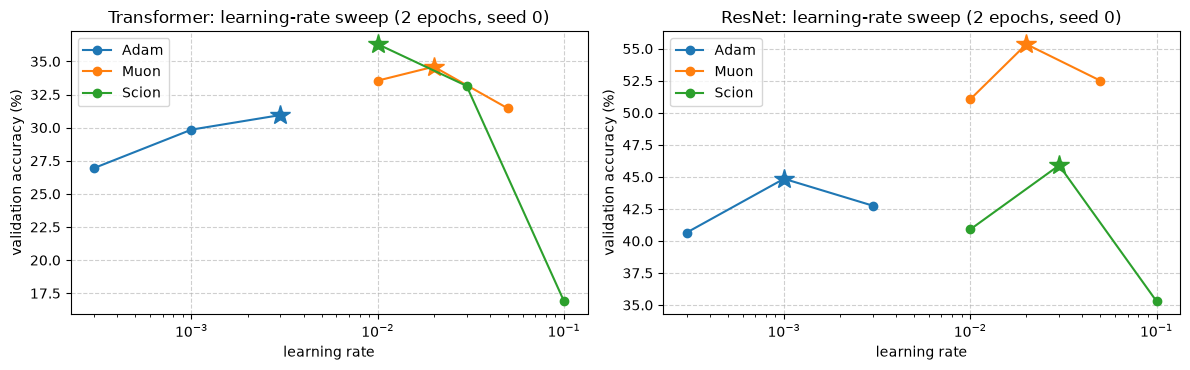

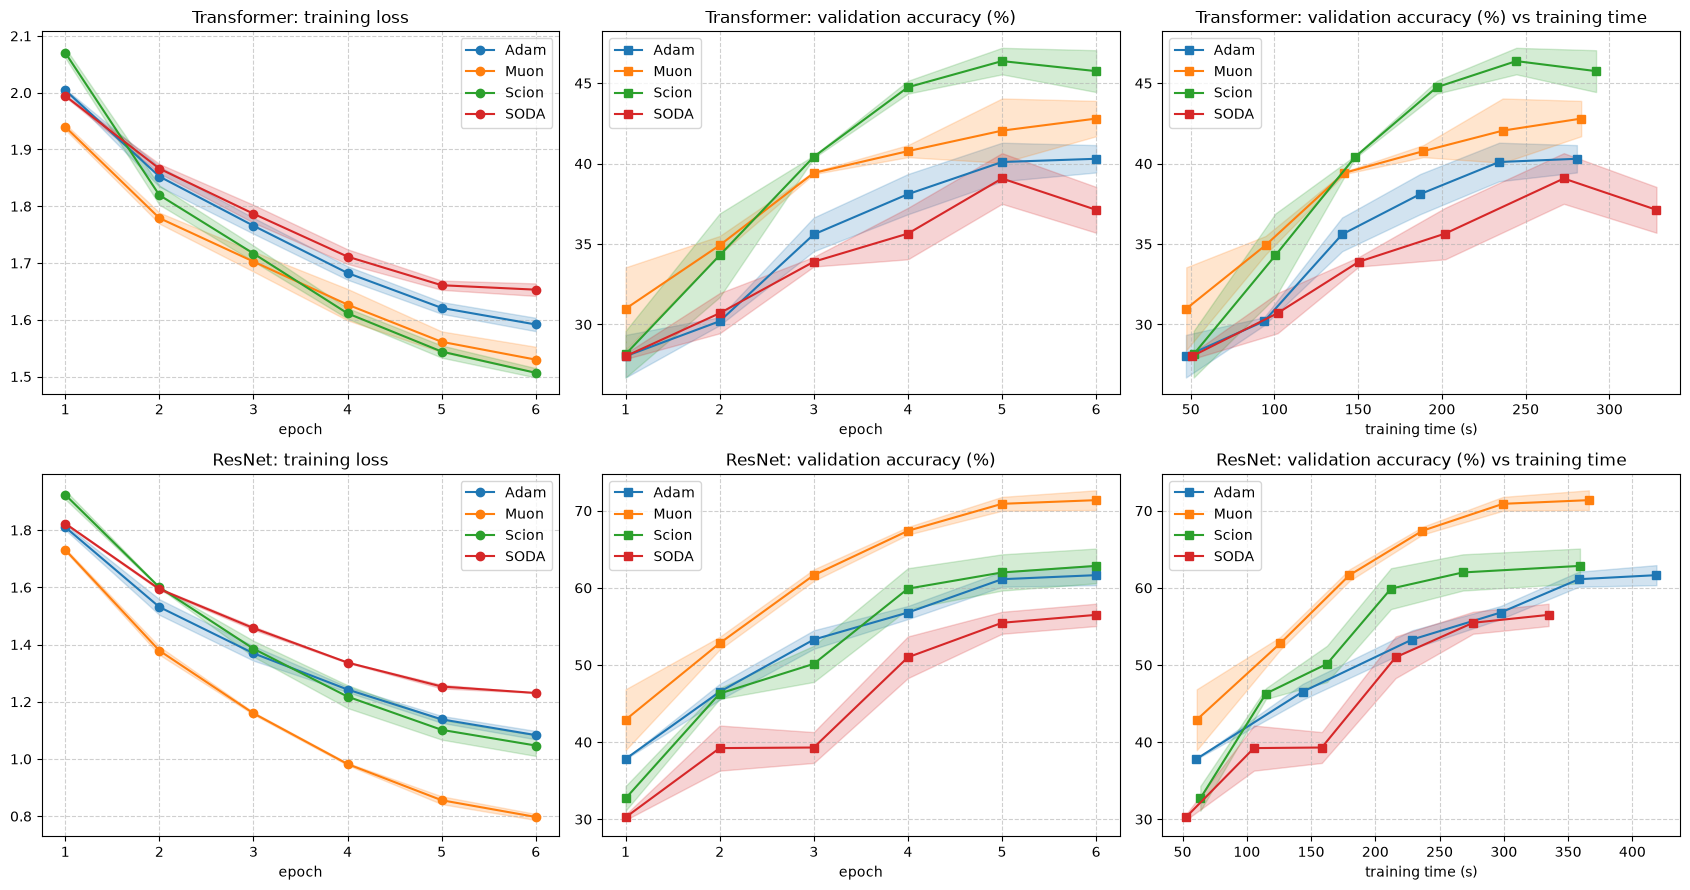

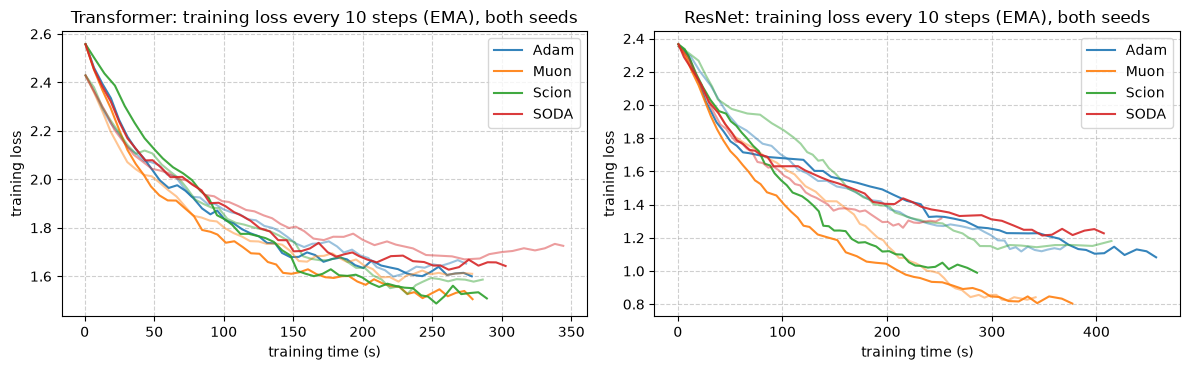

In [14]:
COLORS = {"Adam": "C0", "Muon": "C1", "Scion": "C2", "SODA": "C3"}


def stack(runs, key):
    return np.array([run[key] for run in runs])


# Figure 1: learning-rate sweep
fig, axes = plt.subplots(1, len(MODELS), figsize=(12, 3.8))
for ax, model_name in zip(axes, MODELS):
    for opt_name, accs in sweep[model_name].items():
        lrs = [lr for lr, acc in accs.items() if acc is not None]
        ax.plot(lrs, [accs[lr] for lr in lrs], marker="o", color=COLORS[opt_name], label=opt_name)
        best = best_lr[model_name][opt_name]
        ax.plot([best], [accs[best]], marker="*", markersize=15, color=COLORS[opt_name])
    ax.set_xscale("log")
    ax.set_title(f"{model_name}: learning-rate sweep ({SWEEP_EPOCHS} epochs, seed 0)")
    ax.set_xlabel("learning rate")
    ax.set_ylabel("validation accuracy (%)")
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend()
plt.tight_layout()
plt.show()

# Figure 2: final runs (mean over seeds, shaded band = min/max over seeds)
fig, axes = plt.subplots(len(MODELS), 3, figsize=(17, 9))
epochs_range = np.arange(1, EPOCHS + 1)
for row, model_name in enumerate(MODELS):
    for opt_name in OPTIMIZERS:
        runs = results[model_name][opt_name]
        c = COLORS[opt_name]
        loss, acc, t = stack(runs, "train_loss"), stack(runs, "val_acc"), stack(runs, "train_time").mean(axis=0)
        axes[row, 0].plot(epochs_range, loss.mean(0), marker="o", color=c, label=opt_name)
        axes[row, 0].fill_between(epochs_range, loss.min(0), loss.max(0), color=c, alpha=0.2)
        axes[row, 1].plot(epochs_range, acc.mean(0), marker="s", color=c, label=opt_name)
        axes[row, 1].fill_between(epochs_range, acc.min(0), acc.max(0), color=c, alpha=0.2)
        axes[row, 2].plot(t, acc.mean(0), marker="s", color=c, label=opt_name)
        axes[row, 2].fill_between(t, acc.min(0), acc.max(0), color=c, alpha=0.2)
    titles = ["training loss", "validation accuracy (%)", "validation accuracy (%) vs training time"]
    xlabels = ["epoch", "epoch", "training time (s)"]
    for col in range(3):
        axes[row, col].set_title(f"{model_name}: {titles[col]}")
        axes[row, col].set_xlabel(xlabels[col])
        axes[row, col].grid(True, linestyle="--", alpha=0.6)
        axes[row, col].legend()
plt.tight_layout()
plt.show()

# Figure 3: per-step training loss (exponential moving average) to compare stability within a run
fig, axes = plt.subplots(1, len(MODELS), figsize=(12, 3.8))
for ax, model_name in zip(axes, MODELS):
    for opt_name in OPTIMIZERS:
        for i, run in enumerate(results[model_name][opt_name]):
            raw, smooth, ema = np.array(run["step_loss"]), [], None
            for v in raw:
                ema = v if ema is None else 0.8 * ema + 0.2 * v
                smooth.append(ema)
            ax.plot(run["step_time"], smooth, color=COLORS[opt_name], alpha=0.9 if i == 0 else 0.45,
                    label=opt_name if i == 0 else None)
    ax.set_title(f"{model_name}: training loss every 10 steps (EMA), both seeds")
    ax.set_xlabel("training time (s)")
    ax.set_ylabel("training loss")
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend()
plt.tight_layout()
plt.show()

In [15]:
def fmt(values, digits=2):
    values = np.asarray(values, dtype=float)
    return f"{values.mean():.{digits}f} ± {values.std():.{digits}f}"


def reach_target(run, target):
    """(epoch, training time) of the first epoch whose validation accuracy reaches `target`, or None."""
    for epoch, (acc, t) in enumerate(zip(run["val_acc"], run["train_time"]), start=1):
        if acc >= target:
            return epoch, t
    return None


# Time-to-accuracy target for each model: 90% of the best final validation accuracy (mean over seeds),
# so that the target is meaningful for both architectures.
rows = ["| Model | Optimizer | tuned lr | final train loss | final val acc (%) | best val acc (%) "
        "| test acc (%) | time / epoch (s) | target val acc (%) | epochs to target | time to target (s) |",
        "|---|---|---|---|---|---|---|---|---|---|---|"]
for model_name in MODELS:
    best_final = max(stack(results[model_name][o], "val_acc")[:, -1].mean() for o in OPTIMIZERS)
    target = math.floor(0.9 * best_final)
    for opt_name in OPTIMIZERS:
        runs = results[model_name][opt_name]
        reached = [r for r in (reach_target(run, target) for run in runs) if r is not None]
        if not reached:
            epochs_to, time_to = "not reached", "not reached"
        else:
            note = "" if len(reached) == len(runs) else f" ({len(reached)}/{len(runs)} seeds)"
            epochs_to = f"{np.mean([e for e, _ in reached]):.1f}{note}"
            time_to = f"{np.mean([t for _, t in reached]):.0f}{note}"
        rows.append(
            f"| {model_name} | {opt_name} | {best_lr[model_name][opt_name]:g} "
            f"| {fmt(stack(runs, 'train_loss')[:, -1], 3)} "
            f"| {fmt(stack(runs, 'val_acc')[:, -1])} "
            f"| {fmt(stack(runs, 'val_acc').max(axis=1))} "
            f"| {fmt([r['test_acc'] for r in runs])} "
            f"| {np.mean([r['train_time'][-1] / EPOCHS for r in runs]):.1f} "
            f"| {target} | {epochs_to} | {time_to} |")
display(Markdown("\n".join(rows)))
print(f"Mean ± standard deviation over seeds {SEEDS}; {EPOCHS} epochs on {N_TRAIN:,} training images.")

| Model | Optimizer | tuned lr | final train loss | final val acc (%) | best val acc (%) | test acc (%) | time / epoch (s) | target val acc (%) | epochs to target | time to target (s) |
|---|---|---|---|---|---|---|---|---|---|---|
| Transformer | Adam | 0.003 | 1.592 ± 0.012 | 40.30 ± 0.85 | 40.38 ± 0.92 | 41.45 ± 0.56 | 46.8 | 41 | 5.0 (1/2 seeds) | 236 (1/2 seeds) |
| Transformer | Muon | 0.02 | 1.530 ± 0.023 | 42.80 ± 1.10 | 42.88 ± 1.17 | 43.66 ± 0.63 | 47.2 | 41 | 5.0 | 236 |
| Transformer | Scion | 0.01 | 1.507 ± 0.008 | 45.75 ± 1.30 | 46.38 ± 0.83 | 47.36 ± 0.36 | 48.7 | 41 | 4.0 | 197 |
| Transformer | SODA | 0.003 | 1.653 ± 0.011 | 37.12 ± 1.42 | 39.08 ± 1.57 | 39.95 ± 0.24 | 54.7 | 41 | not reached | not reached |
| ResNet | Adam | 0.001 | 1.083 ± 0.015 | 61.65 ± 1.30 | 61.65 ± 1.30 | 60.32 ± 1.22 | 69.8 | 64 | not reached | not reached |
| ResNet | Muon | 0.02 | 0.797 ± 0.011 | 71.38 ± 1.28 | 71.38 ± 1.28 | 69.00 ± 0.23 | 61.0 | 64 | 4.0 | 237 |
| ResNet | Scion | 0.03 | 1.047 ± 0.036 | 62.85 ± 2.25 | 62.85 ± 2.25 | 61.94 ± 0.99 | 59.9 | 64 | 5.0 (1/2 seeds) | 231 (1/2 seeds) |
| ResNet | SODA | 0.001 | 1.231 ± 0.000 | 56.50 ± 1.45 | 56.50 ± 1.45 | 55.39 ± 0.76 | 55.8 | 64 | not reached | not reached |

Mean ± standard deviation over seeds [0, 1]; 6 epochs on 10,000 training images.


In [16]:
# Wall-clock times on a laptop that is not dedicated to the experiment are noisy (epochs of the same run vary
# by up to ~2x), so we also measure the cost of one optimizer step in isolation: median over 10 steps on one batch.
x_batch, y_batch = next(iter(DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=False)))
rows = ["| Model | forward + backward (ms) | " + " | ".join(f"{o} step (ms)" for o in OPTIMIZERS) + " |",
        "|---|---|" + "---|" * len(OPTIMIZERS)]
for model_name in MODELS:
    fwd_bwd, step_ms = [], []
    for opt_name in OPTIMIZERS:
        torch.manual_seed(0)
        model = MODELS[model_name]().to(device)
        optimizer = make_optimizer(opt_name, model, best_lr[model_name][opt_name])
        t_fb, t_step = [], []
        for i in range(12):
            t0 = time.perf_counter()
            optimizer.zero_grad(set_to_none=True)
            F.cross_entropy(model(x_batch), y_batch).backward()
            t1 = time.perf_counter()
            optimizer.step()
            t2 = time.perf_counter()
            if i >= 2:  # skip warm-up iterations
                t_fb.append(t1 - t0)
                t_step.append(t2 - t1)
        fwd_bwd.append(np.median(t_fb) * 1000)
        step_ms.append(np.median(t_step) * 1000)
    rows.append(f"| {model_name} | {np.median(fwd_bwd):.0f} | " + " | ".join(f"{s:.1f}" for s in step_ms) + " |")
display(Markdown("\n".join(rows)))

| Model | forward + backward (ms) | Adam step (ms) | Muon step (ms) | Scion step (ms) | SODA step (ms) |
|---|---|---|---|---|---|
| Transformer | 542 | 4.5 | 11.6 | 11.4 | 4.9 |
| ResNet | 446 | 10.1 | 34.6 | 35.7 | 12.5 |

### Additional experiment: SODA and the learning-rate schedule

In the final runs, SODA's validation accuracy drops during the last epoch. Our hypothesis is an interaction with the cosine schedule. SODA's pull towards the initialization, $\frac{1}{k+2}(z_0 - x_k)$, does not depend on the learning rate, while the cosine schedule shrinks Adam's steps to zero at the end of training. Unrolling the recursion makes this explicit. With $\Delta_k$ the base optimizer's update at step $k$,
$$
x_K - z_0 = \frac{1}{K+1}\sum_{k=0}^{K-1} (k+2)\,\Delta_k ,
$$
so the distance from the initialization is dominated by the most recent updates, which the cosine schedule makes tiny. To test this, we rerun SODA with the same (tuned) learning rate kept constant.

--- Transformer | SODA, constant lr | lr = 0.003 | seed 0 ---


  epoch 1/6 | train loss 1.9933 | val acc 28.55% | train time   55.5s
  epoch 2/6 | train loss 1.8694 | val acc 30.40% | train time  104.7s
  epoch 3/6 | train loss 1.7894 | val acc 32.00% | train time  152.2s
  epoch 4/6 | train loss 1.7277 | val acc 36.50% | train time  199.4s
  epoch 5/6 | train loss 1.7031 | val acc 41.35% | train time  247.9s
  epoch 6/6 | train loss 1.6776 | val acc 38.65% | train time  294.9s
  test accuracy (10,000 images): 39.34%
--- Transformer | SODA, constant lr | lr = 0.003 | seed 1 ---


  epoch 1/6 | train loss 1.9976 | val acc 27.70% | train time   48.3s
  epoch 2/6 | train loss 1.8728 | val acc 30.40% | train time   96.2s
  epoch 3/6 | train loss 1.8235 | val acc 33.95% | train time  145.2s
  epoch 4/6 | train loss 1.7693 | val acc 33.45% | train time  192.8s
  epoch 5/6 | train loss 1.7346 | val acc 35.30% | train time  240.1s
  epoch 6/6 | train loss 1.6960 | val acc 37.05% | train time  287.1s
  test accuracy (10,000 images): 39.20%
--- ResNet | SODA, constant lr | lr = 0.001 | seed 0 ---


  epoch 1/6 | train loss 1.8169 | val acc 25.65% | train time   40.7s
  epoch 2/6 | train loss 1.6105 | val acc 41.25% | train time   92.4s
  epoch 3/6 | train loss 1.4877 | val acc 42.65% | train time  134.6s
  epoch 4/6 | train loss 1.3783 | val acc 47.05% | train time  175.9s
  epoch 5/6 | train loss 1.3067 | val acc 52.65% | train time  218.1s
  epoch 6/6 | train loss 1.2242 | val acc 55.20% | train time  259.6s
  test accuracy (10,000 images): 54.29%
--- ResNet | SODA, constant lr | lr = 0.001 | seed 1 ---


  epoch 1/6 | train loss 1.8250 | val acc 36.80% | train time   42.5s
  epoch 2/6 | train loss 1.5849 | val acc 38.30% | train time   84.0s
  epoch 3/6 | train loss 1.4501 | val acc 43.35% | train time  125.2s
  epoch 4/6 | train loss 1.3587 | val acc 46.85% | train time  167.0s
  epoch 5/6 | train loss 1.2520 | val acc 43.80% | train time  208.7s
  epoch 6/6 | train loss 1.2093 | val acc 56.50% | train time  250.3s
  test accuracy (10,000 images): 55.15%


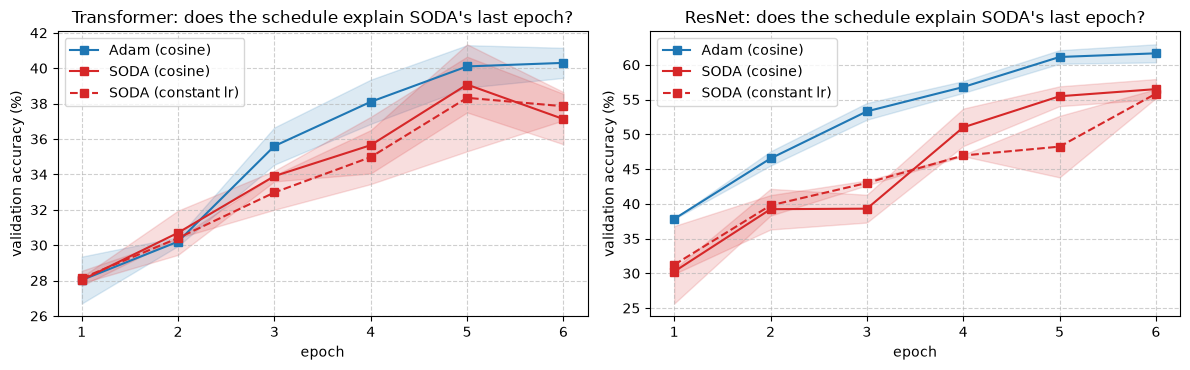

| Model | Variant | val acc, epoch 5 (%) | final val acc, epoch 6 (%) | test acc (%) |
|---|---|---|---|---|
| Transformer | Adam (cosine) | 40.10 ± 1.20 | 40.30 ± 0.85 | 41.45 ± 0.56 |
| Transformer | SODA (cosine) | 39.08 ± 1.57 | 37.12 ± 1.42 | 39.95 ± 0.24 |
| Transformer | SODA (constant lr) | 38.33 ± 3.03 | 37.85 ± 0.80 | 39.27 ± 0.07 |
| ResNet | Adam (cosine) | 61.12 ± 0.98 | 61.65 ± 1.30 | 60.32 ± 1.22 |
| ResNet | SODA (cosine) | 55.47 ± 1.43 | 56.50 ± 1.45 | 55.39 ± 0.76 |
| ResNet | SODA (constant lr) | 48.22 ± 4.43 | 55.85 ± 0.65 | 54.72 ± 0.43 |

In [17]:
# Additional experiment: SODA with a constant learning rate (same lr, seeds and epochs as the final runs).
soda_constant = {}
for model_name in MODELS:
    lr = best_lr[model_name]["SODA"]
    soda_constant[model_name] = []
    for seed in SEEDS:
        print(f"--- {model_name} | SODA, constant lr | lr = {lr:g} | seed {seed} ---", flush=True)
        soda_constant[model_name].append(
            cached_run(model_name, "SODA", lr, EPOCHS, seed, test=True, schedule="constant"))

variants = {"Adam (cosine)": ("C0", lambda m: results[m]["Adam"]),
            "SODA (cosine)": ("C3", lambda m: results[m]["SODA"]),
            "SODA (constant lr)": ("C3", lambda m: soda_constant[m])}
fig, axes = plt.subplots(1, len(MODELS), figsize=(12, 3.8))
for ax, model_name in zip(axes, MODELS):
    for label, (color, get_runs) in variants.items():
        acc = stack(get_runs(model_name), "val_acc")
        ax.plot(epochs_range, acc.mean(0), marker="s", color=color, label=label,
                linestyle="--" if "constant" in label else "-")
        ax.fill_between(epochs_range, acc.min(0), acc.max(0), color=color, alpha=0.15)
    ax.set_title(f"{model_name}: does the schedule explain SODA's last epoch?")
    ax.set_xlabel("epoch")
    ax.set_ylabel("validation accuracy (%)")
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend()
plt.tight_layout()
plt.show()

rows = [f"| Model | Variant | val acc, epoch {EPOCHS - 1} (%) | final val acc, epoch {EPOCHS} (%) | test acc (%) |",
        "|---|---|---|---|---|"]
for model_name in MODELS:
    for label, (_, get_runs) in variants.items():
        runs = get_runs(model_name)
        rows.append(f"| {model_name} | {label} | {fmt(stack(runs, 'val_acc')[:, -2])} "
                    f"| {fmt(stack(runs, 'val_acc')[:, -1])} | {fmt([r['test_acc'] for r in runs])} |")
display(Markdown("\n".join(rows)))

## Discussion

#### Summary

| | Adam | Muon | Scion | SODA |
|---|---|---|---|---|
| Transformer, test acc. (%) | 41.5 ± 0.6 | 43.7 ± 0.6 | **47.4 ± 0.4** | 40.0 ± 0.2 |
| ResNet, test acc. (%) | 60.3 ± 1.2 | **69.0 ± 0.2** | 61.9 ± 1.0 | 55.4 ± 0.8 |

There is no single winner. Muon is the best optimizer on the ResNet by a large margin (+8.7 points over Adam) and the second best on the Transformer. Scion is the best on the Transformer (+5.9 over Adam) but only slightly better than Adam on the ResNet. SODA is the weakest on both architectures in our short budget setting. Both geometry aware optimizers beat the Adam baseline on both models once each optimizer gets its own tuned learning rate.

#### Convergence speed

- Per epoch. Muon is the fastest starter on both models: after one epoch it is 3 points (Transformer) and 5 points (ResNet) above Adam. On the ResNet it keeps that lead for the whole run, reaches the 64 % target after 4 epochs with both seeds, and ends with a much lower training loss (0.80 vs 1.08). On the Transformer, Scion starts like Adam but overtakes everyone from epoch 3 and is the only optimizer that reaches the 41 % target after 4 epochs with both seeds. Adam reaches the Transformer target with only one seed, and neither Adam nor SODA reaches the ResNet target.
- Per second. Orthogonalization is not free, but it is cheap at this scale. One Muon or Scion step costs about 11 ms (Transformer) and 35 ms (ResNet), against 5/10 ms for Adam, while a forward and backward pass costs 540 ms (Transformer) and 450 ms (ResNet). So the extra cost is only 1–6 % of a training step, and the time-to-accuracy ranking is the same as the per-epoch ranking. The per epoch wall clock times in the table vary by about ±20 % because the laptop was also doing other work (e.g. Adam's ResNet epochs appear slower than Muon's although its step is cheaper), so we rely on the isolated step timings for cost and on epochs for speed.

#### Final accuracy and generalization

The test accuracies follow the validation accuracies closely (within 2.5 points), so the learning rate selection on the validation set did not overfit noticeably. The gains of Muon on the ResNet and of Scion on the Transformer are at least 7 times larger than the seed to seed standard deviation, so they are clearly not noise. The differences between Adam and Scion on the ResNet (1.6 points) and between Adam and SODA on the Transformer (1.5 points) are of the order of the noise and should not be over interpreted.

#### Stability

- No run diverged in the final experiments. All training loss curves are smooth (per step plot), and the spread over seeds is small, at most ±1.5 points in final validation accuracy. The exception is Scion on the ResNet (±2.3), where one seed ended 4.5 points below the other.
- Sensitivity to the learning rate is very different across optimizers:
  - Muon is the most forgiving: all three learning rates are within 3–4 points on both models.
  - Adam is similar, about 4 points.
  - Scion is the most sensitive: going from lr 0.03 to 0.1 drops the Transformer from 33 % to 17 % and the ResNet from 46 % to 35 %. One global learning rate drives the spectral, sign and RMS updates at the same time, so a value that is good for one group can be too large for another.

#### Why these results?

- Muon and Scion replace the gradient of each hidden matrix by a normalized direction (approximately $UV^\top$). All singular directions then move at the same rate, regardless of how badly conditioned the gradient is, and the step size controls how much each layer's output can change (steepest descent in the spectral norm). This allows larger steps without instability, which is what we see in the first epochs.
- Scion vs Muon on the ResNet. For 3×3 convolutions, Scion's SpectralConv LMO is divided by $k^2 = 9$. With the tuned lr = 0.03, a hidden conv step therefore has spectral norm about $0.03 \cdot \sqrt{c_\text{out}/c_\text{in}}/9 \approx 0.003$, roughly 6× smaller than Muon's ($0.02$). Scion could not compensate with a larger lr, because the same lr also scales the RMS updates of the biases and BatchNorm gains and the sign update of the head, and lr = 0.1 already degrades training. The authors recommend tuning the radius of each layer group separately; we only tuned one global lr, which most likely explains part of the gap.
- Scion vs Muon on the Transformer. Here Scion's hidden steps are even 2–3× smaller than Muon's, yet Scion wins. The main difference is in the non-hidden parameters. Scion also applies normalized updates to the patch embedding (spectral), the head (sign) and the LayerNorm, bias and positional parameters (RMS). Muon delegates them to an auxiliary AdamW with a fixed lr of 1e-3, while Adam alone preferred 3e-3 on this model. We did not tune this auxiliary lr, so Muon is probably handicapped on the Transformer; this is a hypothesis we could not test within our budget.
- SODA has the highest training loss on both models (1.65 vs 1.59 for Adam on the Transformer, 1.23 vs 1.08 on the ResNet). So it is underfitting, not overfitting. Unrolling the update gives $x_K - z_0 = \frac{1}{K+1}\sum_k (k+2)\Delta_k$: early updates are strongly down-weighted, and for constant updates the distance travelled from the initialization is about half of Adam's. This is a strong regularizer. In our regime (6 epochs, training loss still far from 0), the models are far from fitting the training set and there is no overfitting to fight, so regularization can only slow optimization down. SODA's promise, removing the need to tune weight decay, targets long training runs where regularization matters, which we cannot afford on a CPU.
- The additional experiment rejects our schedule hypothesis. With a constant learning rate, SODA is not better (test 39.3 % vs 40.0 % on the Transformer, 54.7 % vs 55.4 % on the ResNet). The last epoch drop also appears in one constant-lr run. With 2,000 validation images the standard error of an accuracy around 40 % is about 1.1 points, so most of that drop is evaluation noise on top of SODA's slower progress, not an effect of the cosine schedule.

#### Limitations

- Small budget: 10,000 training images, 6 epochs, CPU only, and 2 seeds, so standard deviations from two runs are rough.
- The learning rates were tuned with a 2 epoch proxy. For the Transformer, the best values of Adam (3e-3) and Scion (0.01) lie on the edge of their grids; for Scion, the pilot run showed that 0.003 is worse.
- We tuned only the learning rate, not momentum, weight decay, Muon's auxiliary lr or Scion's per-group radii.
- The conclusions could change with full-length training, where regularization (and therefore SODA) matters more.

Take away: with a modest tuning budget, Muon is the most reliable choice. It is the best or second best on both architectures and the least sensitive to the learning rate, for a small per step overhead. Scion can be the best, but it needs per layer tuning. SODA did not help in this short horizon regime.

## Reflection on AI-assisted coding

We took the vibe part of this exercise at first. We described what we wanted to Gemini in plain words, pasted back every error message, and kept whatever ran. That part really did work: within a few iterations we had a ViT, a ResNet, three optimizers we had never implemented before and a training loop that produced plots.

The friction was mostly practical. The official CIFAR-10 server was painfully slow for us, so the assistant suggested a mirror. We only kept it after checking that torchvision verifies the archive's MD5, so the data is guaranteed to be the same. Being CPU only forced us to shrink everything (10k training images, 6 epochs) and to cache finished runs. Our first rewrite of SODA during the revision crashed at the very first step. It stored the initial weights inside the optimizer state, so Adam thought it was already initialized and looked for moment buffers that did not exist. 

The real lesson came later, and it was a bit humbling. Our first notebook ran, produced nice plots, and was largely wrong in the parts that mattered:
- SODA had two constants that are nowhere in the paper (an offset of 100 in the 1/k schedule and an extra factor lr·10). Together they made the pull towards the initialization about 10⁻⁵ instead of 1/(k+2). So our SODA was just Adam without weight decay. The giveaway was in our own results: on the Transformer, the Adam and SODA curves were identical to the second decimal, and we had not noticed.
- Scion's learning rate (1e-3) was copied from Adam's world. With normalized updates, that meant steps hundreds of times smaller than in the reference configuration. Our first conclusion, "Scion is the worst optimizer", was really "our Scion was badly tuned".
- Muon was also orthogonalizing the classifier head and the first layer, which the authors explicitly say not to do.

We caught these issues when we went back over the notebook with a second assistant (Claude Code), comparing every update rule with the official repositories (KellerJordan/Muon, LIONS-EPFL/scion, tmpethick/soda_code). Then we rebuilt the experiment more carefully:
- implementations that follow the references;
- a small check that our SODA matches the reference formula exactly;
- the same learning rate tuning budget for every optimizer;
- a proper validation split, two seeds per run, and a test set we touch only once.

The conclusions changed a lot, which is exactly why it was worth doing:
- Scion went from "worst optimizer" to the best one on the Transformer.
- SODA went from "identical to Adam" to clearly behind Adam.


One more thing surprised us. When SODA's accuracy dropped in the last epoch, the explanation that we and the assistant found most convincing was the cosine schedule, and we even had a neat formula supporting it. We ran the extra experiment with a constant learning rate, and it proved us wrong.

What we take away: vibe coding is great for data pipelines, training loops, plotting and for getting unstuck quickly. It is risky for the few lines that are the content of the exercise, like an optimizer's update rule. There the model happily fills the gaps with plausible looking constants, and the code still runs.In short, the AI made us faster, but it did not make us right. Being right still required reading the paper, testing the code and questioning our own explanations.

AI conversations used for this part: Gemini, https://share.gemini.google/nfnFQJoHiXTZ, then revised with Claude Code